# Take-home midterm: automatic camera calibration

Calibrating a camera means recovering the numbers that turn 3D points into pixels: the focal length $f$ in pixels, the principal point, lens distortion, and how the camera is tilted. The classical way puts an object of exactly known geometry in front of the camera: a checkerboard. Automatic calibration does without it. Vertical lines in a room show the direction of gravity. A person has about the same height wherever they stand, which gives a rough scale. NVIDIA's [AutoMagicCalib](https://github.com/NVIDIA-AI-IOT/auto-magic-calib) calibrates whole camera networks this way, from footage of people walking.

In this midterm you calibrate **your own laptop webcam** three ways and compare them:

1. With a checkerboard. This is your ground truth, and you take its method apart step by step.
2. With [GeoCalib](https://arxiv.org/abs/2409.06704), a neural network that calibrates from one ordinary photo. You study what the network predicts and how the camera follows from it.
3. From a video of a person walking, with the geometry that AutoMagicCalib uses.

**Reading.** The course section [From World Points to Pixels](https://aegean.ai/aiml-common/lectures/sensor-models/cameras/camera-modeling/index) (camera models and checkerboard calibration) and the section [Single View Metrology](https://aegean.ai/aiml-common/lectures/3d-reconstruction/single-view-metrology/index) (vanishing points and the horizon line).

**How this midterm works.**

- Cells marked **Provided** are complete. Run them, but do not edit them.
- Cells marked **Task** contain a function or a few lines for you to write. They start with `raise NotImplementedError` or with variables set to `None`; replace those with your code.
- Most tasks are followed by a **Check** cell. A check prints `passed` when your code is right, and raises an error that explains what is wrong otherwise. Later parts use your earlier functions, so do not move on until the check passes.
- Some results depend on your camera and your room, not only on your code. Those checks print a **warning** instead of failing. A warning is not a lost point: explain what you see in the questions.
- The **Questions** ask you to explain what you did and observed. Answer in the markdown cells provided, in your own words.
- Use a GPU runtime. The neural networks run on a CPU too, only much more slowly.

| Part | Topic | Points |
|---|---|---|
| 1 | The checkerboard baseline, explained | 25 |
| 2 | Single-image calibration with GeoCalib | 35 |
| 3 | Calibration from a person walking, as in NVIDIA AutoMagicCalib | 25 |
| 4 | Comparison | 15 |

## Your data

You capture three kinds of data with your laptop's webcam. Run the capture script [`capture.py`](https://github.com/pantelis/eng-ai-agents/blob/main/notebooks/assignments/topics/automatic-camera-calibration/dev/capture.py) on your laptop, not in Colab, because Colab cannot open a local camera. The script needs `opencv-python` and `numpy`.

```bash
python capture.py list                       # find your color webcam's index
python capture.py capture --device 0 --pattern 10 7 --square-mm 21.5
```

Pass your own board's **inner-corner** count to `--pattern` (a board with 11 by 8 squares has 10 by 7 inner corners) and the measured side of one square to `--square-mm`. In the preview window, `c` saves a checkerboard view, `s` saves an ordinary scene, `v` starts and stops a video, and `q` quits.

- **About 20 checkerboard views.** Hold the board so it fills a third to half of the frame. Cover the center, the four corners and the edges of the image, tilt the board up to about 45 degrees in different directions, and hold still before each save. Good light helps.
- **About 10 scenes with no checkerboard,** each a different view: a cluttered corner with vertical lines, a blank wall, the lid tilted back (looking up) and tilted forward (looking down). Then capture four scenes of the same view at four lid angles. Lay your phone flat on the back of the lid and read the tilt in degrees each time: on an iPhone with the Level tab of the built-in Measure app, on Android with the Bubble Level app. In Measure, do not tap the screen between readings, because a tap resets the zero. Save each with `--tag tilt<reading>`, for example `--tag tilt95`. Only the **changes** between readings matter, so it does not matter how the app defines zero.
- **A 30 to 60 second video of yourself walking** back and forth across the room with the laptop completely still, your whole body in view, at several distances. Read the lid's angle with the phone app, the same way, before you start, and write it down.

**Keep your captures in your Google Drive.** Upload the whole `captures` folder to `My Drive/cv-midterm/captures` (drag it into drive.google.com, or use the Google Drive desktop app). The setup cell mounts your Drive and reads it from there, so your data survives the end of a Colab session and never needs to go into your repository. If you store it elsewhere, change `CAPTURES` in the setup cell. Until your captures are in place, every cell runs on a sample captured on a ThinkPad P16 webcam.

**The sample is only for getting started. Every result you hand in must come from your own captures. Any part answered with the sample data is penalized.**

## Setup

**Provided.** Installs GeoCalib, imports everything, mounts your Google Drive in Colab, and loads your captures from `CAPTURES`. If that folder has no `session.json`, it tries a local `captures` folder and then falls back to the sample.

In [2]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("geocalib") is None:
    # pinned to the tested GeoCalib revision, so everyone runs the same code as the solutions
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/cvg/GeoCalib@97b8968e7798a66bf04fcf791fb535624241bda7#egg=geocalib"])

In [2]:
import json
import urllib.request
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SAMPLE = "https://artifacts.aegeanai.com/datasets/automatic-camera-calibration/thinkpad-p16"
CAPTURES = "/content/drive/MyDrive/cv-midterm/captures"  # change this if your captures are elsewhere in your Drive

try:
    from google.colab import drive

    drive.mount("/content/drive")
except ImportError:
    pass  # not running in Colab


def download(url, target):
    # the file host rejects Python's default user agent, so send a named one
    req = urllib.request.Request(url, headers={"User-Agent": "eaia-course-notebook/1.0"})
    with urllib.request.urlopen(req) as r, open(target, "wb") as f:
        f.write(r.read())


def fetch_sample(dest):
    dest.mkdir(parents=True, exist_ok=True)
    download(f"{SAMPLE}/session.json", dest / "session.json")
    for entry in json.loads((dest / "session.json").read_text())["files"]:
        target = dest / entry["file"]
        target.parent.mkdir(parents=True, exist_ok=True)
        if not target.exists():
            download(f"{SAMPLE}/{entry['file']}", target)


DATA = next((Path(p) for p in (CAPTURES, "captures") if (Path(p) / "session.json").exists()), None)
if DATA is None:
    print("no captures found in your Drive or in ./captures: using the sample data")
    DATA = Path("sample")
    fetch_sample(DATA)

SESSION = json.loads((DATA / "session.json").read_text())
PATTERN = tuple(SESSION["pattern_inner_corners"])
SQUARE_MM = SESSION.get("square_mm")
if not SQUARE_MM:
    print("session.json has no square size: using 1 (board units). The intrinsics are unaffected; distances are in squares.")
    SQUARE_MM = 1.0
W, H = SESSION["width"], SESSION["height"]
BOARDS = sorted((DATA / "checkerboard").glob("*.png"))
SCENES = sorted((DATA / "scenes").glob("*.png"))
# recording order from session.json, so VIDEOS[-1] is the latest take even across --tag values
_ORDER = {f["file"].replace("\\", "/").rsplit("/", 1)[-1]: i for i, f in enumerate(SESSION["files"])}
VIDEOS = sorted(
    (p for ext in ("*.mp4", "*.avi") for p in (DATA / "video").glob(ext)),
    key=lambda p: (_ORDER.get(p.name, -1), p.name),
)
print(f"camera: {SESSION['camera_name']} at {W}x{H}; board {PATTERN} inner corners, {SQUARE_MM} mm squares")
print(f"{len(BOARDS)} checkerboard views, {len(SCENES)} scenes, {len(VIDEOS)} videos; device {DEVICE}")

Mounted at /content/drive
camera: unknown (name not available on this system) at 1280x720; board (10, 7) inner corners, 18.9 mm squares
20 checkerboard views, 19 scenes, 2 videos; device cuda


In [4]:
print("Dataset:", DATA)
print("Checkerboards:", len(BOARDS))
print("Scenes:", len(SCENES))
print("Videos:", [v.name for v in VIDEOS])

Dataset: /content/drive/MyDrive/cv-midterm/captures
Checkerboards: 20
Scenes: 19
Videos: ['walk_000.mp4', 'walk_001.mp4']


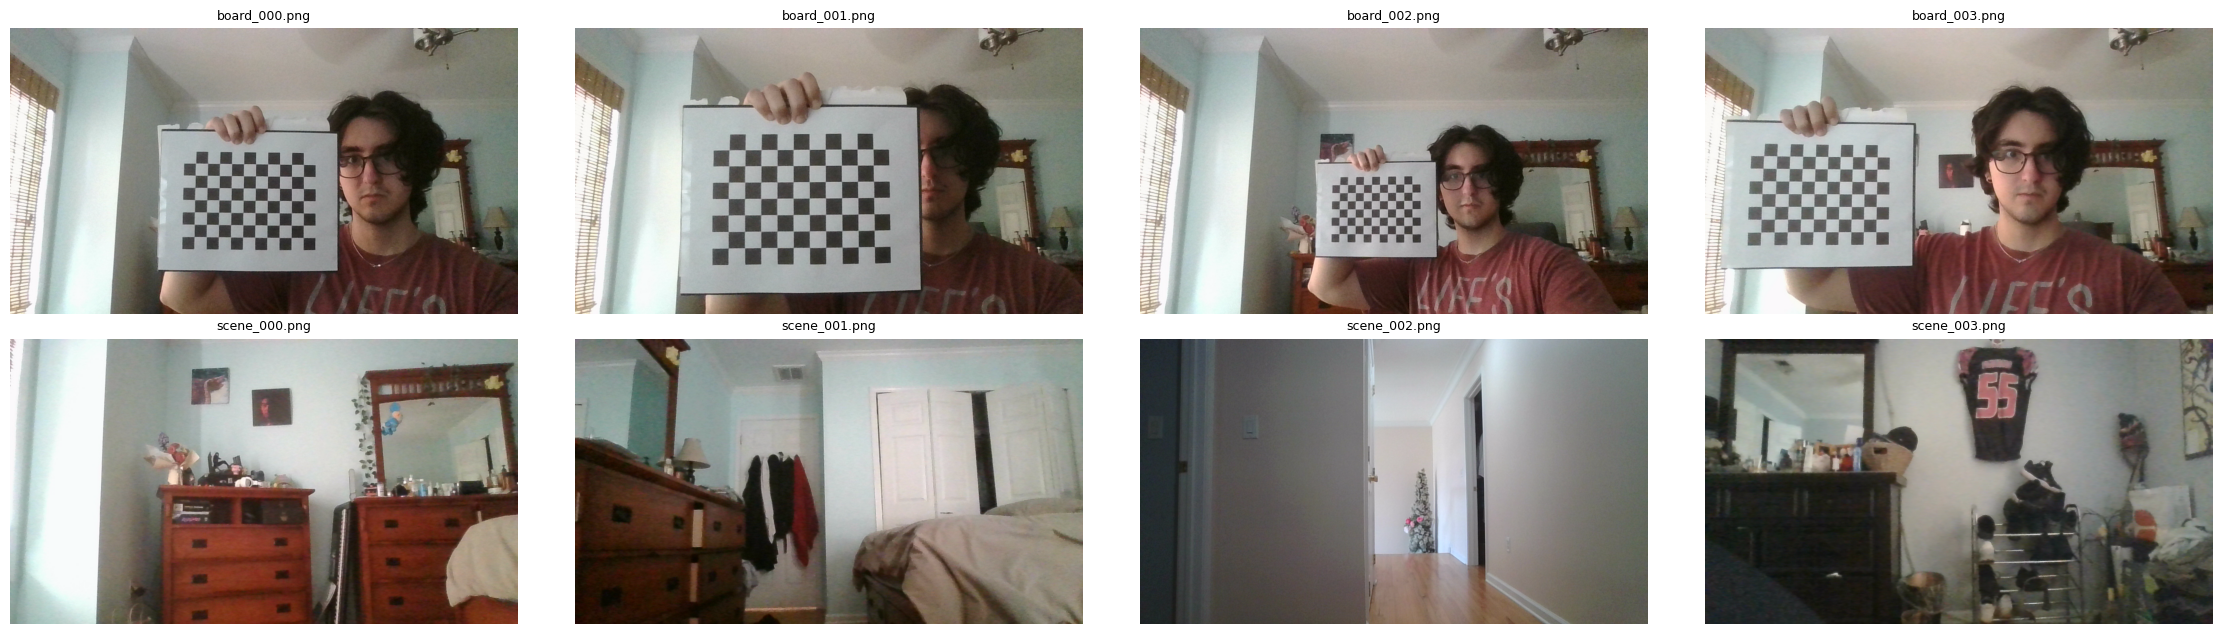

In [5]:
def warn_unless(ok, message):
    # for results that depend on your camera and room rather than on your code
    if not ok:
        print("warning:", message)


def load_rgb(path):
    return cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)


def show_images(paths, titles=None, cols=4, size=3.2):
    rows = (len(paths) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size * 16 / 9, rows * size))
    for ax in np.ravel(axes):
        ax.axis("off")
    for i, (ax, p) in enumerate(zip(np.ravel(axes), paths)):
        ax.imshow(load_rgb(p))
        ax.set_title(titles[i] if titles else Path(p).name, fontsize=9)
    plt.tight_layout()
    plt.show()


show_images(BOARDS[:4] + SCENES[:4])

## Part 1. The checkerboard baseline, explained (25 points)

Your checkerboard calibration is the reference for everything that follows, so you need to trust it, and that means understanding it. The method is Zhang's: every view of a flat board gives a homography, every homography gives two equations on the intrinsic matrix $\mathbf{K}$, and a nonlinear refinement then minimizes the reprojection error over all views. The course section [From World Points to Pixels](https://aegean.ai/aiml-common/lectures/sensor-models/cameras/camera-modeling/index) derives each step (sections 39.7.1 to 39.7.4).

**Provided.** Detects the inner corners of the board in every view. `findChessboardCornersSB` copes with small, dim and tilted boards much better than the older `findChessboardCorners`.

In [6]:
BOARD_MM = np.zeros((PATTERN[0] * PATTERN[1], 3), np.float32)
BOARD_MM[:, :2] = np.mgrid[0:PATTERN[0], 0:PATTERN[1]].T.reshape(-1, 2) * SQUARE_MM  # corner positions on the board, mm

object_points, image_points, board_files = [], [], []
for path in BOARDS:
    gray = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2GRAY)
    found, corners = cv2.findChessboardCornersSB(gray, PATTERN, cv2.CALIB_CB_EXHAUSTIVE | cv2.CALIB_CB_ACCURACY)
    if found:
        object_points.append(BOARD_MM)
        image_points.append(corners.astype(np.float32))
        board_files.append(path)
print(f"board found in {len(board_files)} of {len(BOARDS)} views")

board found in 20 of 20 views


### Task 1.1. Calibrate

Write `calibrate(object_points, image_points)`. Call `cv2.calibrateCamera` with image size `(W, H)` and return `rms, K, dist, rvecs, tvecs`. Then compute the horizontal and vertical fields of view in degrees from $\mathbf{K}$. Use the principal point, which need not be at the image center: the horizontal field of view is $\arctan(c_x / f_x) + \arctan((W - c_x) / f_x)$, and the vertical one uses $c_y$, $f_y$ and $H$ the same way.

In [7]:
def calibrate(object_points, image_points):
    rms, K, dist, rvecs, tvecs = cv2.calibrateCamera(object_points, image_points, (W, H), None, None)

    return rms, K, dist, rvecs, tvecs


rms, K, dist, rvecs, tvecs = calibrate(object_points, image_points)

f_x = K[0, 0]
f_y = K[1, 1]
c_x = K[0, 2]
c_y = K[1, 2]

hfov = np.degrees(np.arctan(c_x / f_x) + np.arctan((W - c_x) / f_x))  # degrees
vfov = np.degrees(np.arctan(c_y / f_x) + np.arctan((H-c_y) / f_y))  # degrees

In [8]:
F_REF = (K[0, 0] + K[1, 1]) / 2  # the reference focal length for the rest of the midterm
print(f"RMS reprojection error {rms:.3f} px")
print(f"fx {K[0, 0]:.1f}  fy {K[1, 1]:.1f}  cx {K[0, 2]:.1f}  cy {K[1, 2]:.1f}  (image center {W / 2:.0f}, {H / 2:.0f})")
print(f"distortion k1 k2 p1 p2 k3: {np.round(dist.ravel()[:5], 4)}")
print(f"field of view {hfov:.1f} x {vfov:.1f} degrees")
assert hfov is not None and vfov is not None, "compute hfov and vfov"
assert abs(hfov - np.degrees(2 * np.arctan(W / (2 * K[0, 0])))) < 0.2 * hfov, "hfov does not match K: use the formula above, in degrees"
warn_unless(rms < 2.0, "RMS above 2 px: check the pattern size and remove blurred views")
warn_unless(abs(K[0, 0] - K[1, 1]) < 0.05 * K[0, 0], "fx and fy differ by more than 5%: is the image resized non-uniformly?")
warn_unless(40 < hfov < 120, "a laptop webcam usually has a horizontal field of view of 50 to 90 degrees")
print("passed")

RMS reprojection error 0.935 px
fx 900.1  fy 905.7  cx 652.3  cy 395.3  (image center 640, 360)
distortion k1 k2 p1 p2 k3: [-0.1873  0.6101  0.0077  0.0036 -0.6834]
field of view 70.8 x 43.4 degrees
passed


### Task 1.2. One homography per view

The board is flat, so its corners satisfy $Z = 0$ in the board frame, and the projection of the board plane onto the image is a homography: $\tilde{\mathbf{x}} \sim \mathbf{H}\, (X, Y, 1)^\top$ with $\mathbf{H} = \mathbf{K}\, [\mathbf{r}_1\ \mathbf{r}_2\ \mathbf{t}]$, where $\mathbf{r}_1, \mathbf{r}_2$ are the first two columns of the board's rotation.

Write `homography(board_xy, corners)`, which returns the $3 \times 3$ homography from board coordinates in mm to pixels, using `cv2.findHomography`. Then write `homography_error(Hm, board_xy, corners)`, which maps the board points through $\mathbf{H}$ and returns the median distance in pixels to the detected corners.

In [9]:
def homography(board_xy, corners):
    Hm, mask = cv2.findHomography(board_xy, corners)
    return Hm


def homography_error(Hm, board_xy, corners):
    points = board_xy.astype(np.float32).reshape(-1, 1, 2)

    predicted = cv2.perspectiveTransform(points, Hm).reshape(-1, 2)
    actual = corners.reshape(-1, 2)

    return np.median(np.linalg.norm(predicted - actual, axis=1))

In [10]:
homographies = [homography(BOARD_MM[:, :2], c) for c in image_points]
h_err = [homography_error(Hm, BOARD_MM[:, :2], c) for Hm, c in zip(homographies, image_points)]
print("median homography error per view (px):", np.round(h_err, 2))
assert max(h_err) < 5, "a homography should map the board onto its corners to within a few pixels"
print("passed")

median homography error per view (px): [0.15 0.27 0.13 0.42 0.46 0.75 0.29 0.63 0.94 0.61 0.86 1.4  1.2  0.88
 0.95 0.57 0.73 0.59 0.34 0.65]
passed


### Task 1.3. Two equations per view

Because $\mathbf{r}_1$ and $\mathbf{r}_2$ are orthonormal, every homography gives two equations on the symmetric matrix $\mathbf{B} = \mathbf{K}^{-\top}\mathbf{K}^{-1}$:

$$
\mathbf{h}_1^\top \mathbf{B}\, \mathbf{h}_2 = 0, \qquad \mathbf{h}_1^\top \mathbf{B}\, \mathbf{h}_1 = \mathbf{h}_2^\top \mathbf{B}\, \mathbf{h}_2,
$$

where $\mathbf{h}_i$ is column $i$ of $\mathbf{H}$. Writing $\mathbf{b} = (B_{11}, B_{12}, B_{22}, B_{13}, B_{23}, B_{33})$, each one is linear in $\mathbf{b}$: $\mathbf{h}_i^\top \mathbf{B}\, \mathbf{h}_j = \mathbf{v}_{ij}^\top \mathbf{b}$ with

$$
\mathbf{v}_{ij} = \begin{bmatrix} h_{1i} h_{1j} & h_{1i} h_{2j} + h_{2i} h_{1j} & h_{2i} h_{2j} & h_{3i} h_{1j} + h_{1i} h_{3j} & h_{3i} h_{2j} + h_{2i} h_{3j} & h_{3i} h_{3j} \end{bmatrix}^\top,
$$

where $h_{ki}$ is the entry in row $k$, column $i$ of $\mathbf{H}$. Stacking $\mathbf{v}_{12}^\top$ and $(\mathbf{v}_{11} - \mathbf{v}_{22})^\top$ for every view gives a system $\mathbf{V}\mathbf{b} = 0$, solved by SVD, and $\mathbf{K}$ follows from $\mathbf{b}$ in closed form.

Write `v_ij(Hm, i, j)` for 1-based `i` and `j`. The provided cell builds $\mathbf{V}$, solves it, and recovers $\mathbf{K}$.

In [11]:
def v_ij(Hm, i, j):
    h_i = Hm[:, i - 1]
    h_j = Hm[:, j - 1]

    return np.array([
        h_i[0] * h_j[0],
        h_i[0] * h_j[1] + h_i[1] * h_j[0],
        h_i[1] * h_j[1],
        h_i[2] * h_j[0] + h_i[0] * h_j[2],
        h_i[2] * h_j[1] + h_i[1] * h_j[2],
        h_i[2] * h_j[2]
    ])


In [12]:
# test v_ij on random matrices: v_ij(H, i, j) . b must equal h_i^T B h_j for any symmetric B
rng = np.random.default_rng(1)
for _ in range(5):
    H_test, M = rng.normal(size=(3, 3)), rng.normal(size=(3, 3))
    B_test = M + M.T
    b_test = B_test[[0, 0, 1, 0, 1, 2], [0, 1, 1, 2, 2, 2]]
    for i, j in [(1, 1), (1, 2), (2, 2)]:
        lhs = H_test[:, i - 1] @ B_test @ H_test[:, j - 1]
        assert np.isclose(v_ij(H_test, i, j) @ b_test, lhs), f"v_ij({i}, {j}) . b differs from h_{i}^T B h_{j}: check its entries"
print("v_ij passed")

v_ij passed


In [13]:
def zhang_closed_form(homographies):
    V = []
    for Hm in homographies:
        Hm = Hm / np.linalg.norm(Hm)
        V.append(v_ij(Hm, 1, 2))
        V.append(v_ij(Hm, 1, 1) - v_ij(Hm, 2, 2))
    b = np.linalg.svd(np.array(V))[2][-1]
    if b[0] < 0:
        b = -b
    B11, B12, B22, B13, B23, B33 = b
    v0 = (B12 * B13 - B11 * B23) / (B11 * B22 - B12**2)
    lam = B33 - (B13**2 + v0 * (B12 * B13 - B11 * B23)) / B11
    alpha = np.sqrt(lam / B11)
    beta = np.sqrt(lam * B11 / (B11 * B22 - B12**2))
    gamma = -B12 * alpha**2 * beta / lam
    u0 = gamma * v0 / beta - B13 * alpha**2 / lam
    return np.array([[alpha, gamma, u0], [0, beta, v0], [0, 0, 1]]), len(V)


K_closed, n_equations = zhang_closed_form(homographies)
print(f"{n_equations} equations from {len(homographies)} views")
print("closed form K:\n", np.round(K_closed, 1))
print(f"focal length: closed form {K_closed[0, 0]:.1f}, after refinement {K[0, 0]:.1f}")
assert np.isfinite(K_closed).all(), "the closed form failed: check v_ij against the formula, entry by entry"
warn_unless(abs(K_closed[0, 0] - K[0, 0]) < 0.15 * K[0, 0],
            "the closed form is more than 15% from the refined focal length; noisy or strongly distorted views can cause this")
print("passed")

40 equations from 20 views
closed form K:
 [[927.2  -7.3 625.6]
 [  0.  940.4 382.8]
 [  0.    0.    1. ]]
focal length: closed form 927.2, after refinement 900.1
passed


### Task 1.4. What the refinement minimizes

`calibrateCamera` starts from the closed form and then adjusts $\mathbf{K}$, the distortion and every view's pose to minimize the **reprojection error**: the distance between each detected corner and the projection of the corresponding board point. Write `reprojection_errors(...)`, which uses `cv2.projectPoints` to return the RMS reprojection error of each view in pixels.

In [14]:
def reprojection_errors(object_points, image_points, rvecs, tvecs, K, dist):
    errors = []

    for obj, img, rvec, tvec in zip(object_points, image_points, rvecs, tvecs):
        projected, _ = cv2.projectPoints(obj, rvec, tvec, K, dist)

        projected = projected.reshape(-1, 2)
        img = img.reshape(-1, 2)

        squared_errors = np.sum((projected - img) ** 2, axis=1)
        rms = np.sqrt(np.mean(squared_errors))

        errors.append(rms)

    return np.array(errors)


In [15]:
view_err = reprojection_errors(object_points, image_points, rvecs, tvecs, K, dist)
overall = np.sqrt(np.mean(view_err**2))
print(f"per-view RMS: {np.round(view_err, 2)}; overall {overall:.3f} px (calibrateCamera reported {rms:.3f})")
assert abs(overall - rms) < 0.05 * rms + 0.01, "the per-view errors should combine to the RMS that calibrateCamera reports"
print("passed")

per-view RMS: [0.2  0.32 0.21 0.35 0.63 0.62 0.4  0.8  1.29 0.8  1.13 1.72 1.4  1.18
 1.46 0.86 0.86 0.74 0.86 0.9 ]; overall 0.935 px (calibrateCamera reported 0.935)
passed


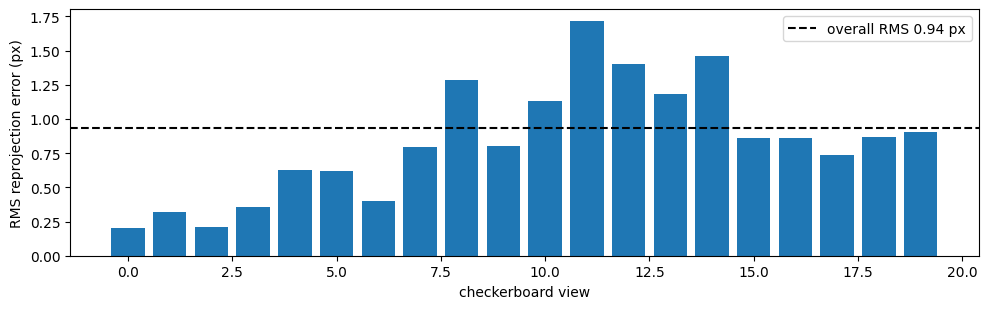

In [16]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(range(len(view_err)), view_err, color="tab:blue")
ax.axhline(rms, color="black", linestyle="--", label=f"overall RMS {rms:.2f} px")
ax.set_xlabel("checkerboard view")
ax.set_ylabel("RMS reprojection error (px)")
ax.legend()
plt.tight_layout()
plt.show()

### Task 1.5. The influence of each view

Leave each view out in turn, recalibrate from the rest, and record the focal length $f_x$. Store the results in `f_leave_one_out`, one value per view.

In [17]:
f_leave_one_out = []

for i in range(len(object_points)):
    obj = [p for j, p in enumerate(object_points) if j != i]
    img = [p for j, p in enumerate(image_points) if j != i]

    _, K_new, _, _, _ = calibrate(obj, img)
    f_leave_one_out.append(K_new[0, 0])

f_leave_one_out = np.array(f_leave_one_out)

In [18]:
spread = 100 * (f_leave_one_out.max() - f_leave_one_out.min()) / K[0, 0]
print(f"leave-one-out fx: {f_leave_one_out.min():.1f} to {f_leave_one_out.max():.1f} ({spread:.1f}% of fx)")
assert len(f_leave_one_out) == len(object_points)
print("passed")

leave-one-out fx: 894.9 to 907.7 (1.4% of fx)
passed


**Provided.** Near-frontal views against tilted views. The tilt of each board view is the angle between the board's normal and the camera's optical axis. The cell calibrates once from the five most frontal views and once from the five most tilted, and compares the uncertainty that `calibrateCameraExtended` reports for $f_x$.

In [19]:
tilts = np.array([np.degrees(np.arccos(abs(cv2.Rodrigues(r)[0][2, 2]))) for r in rvecs])
order = np.argsort(tilts)
for label, idx in [("5 most frontal", order[:5]), ("5 most tilted", order[-5:])]:
    out = cv2.calibrateCameraExtended([object_points[i] for i in idx], [image_points[i] for i in idx], (W, H), None, None)
    K_s, std = out[1], out[5]
    print(f"{label:15s} tilts {np.round(tilts[idx]).astype(int)} deg -> fx {K_s[0, 0]:7.1f} +/- {std[0, 0]:5.1f} px")

5 most frontal  tilts [3 4 4 6 7] deg -> fx  1097.0 +/-  73.4 px
5 most tilted   tilts [35 39 41 46 53] deg -> fx   904.6 +/-   6.6 px


**Provided.** The same image before and after removing the lens distortion.

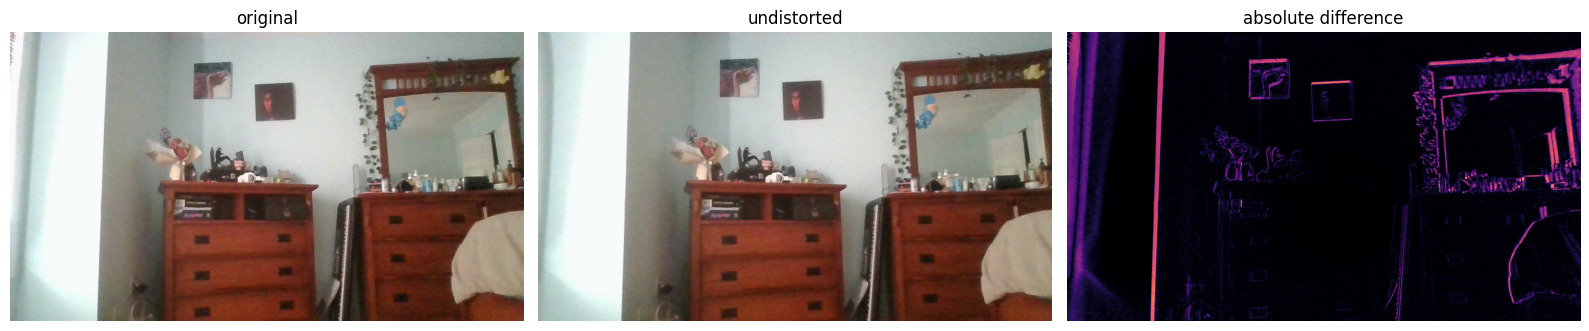

In [20]:
img = load_rgb(SCENES[0])
und = cv2.undistort(img, K, dist)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
axes[0].imshow(img); axes[0].set_title("original")
axes[1].imshow(und); axes[1].set_title("undistorted")
axes[2].imshow(np.abs(img.astype(int) - und.astype(int)).sum(-1), cmap="magma"); axes[2].set_title("absolute difference")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Question 1.1. Views needed to recover K

Why does every view of the board give exactly two equations on $\mathbf{K}$, and why does that mean you need at least three views when $\mathbf{K}$ has five unknowns (or two views if the skew is fixed at zero)?

The reason that each checkerboard gives two equations is that the homography gives two constraints. These constraints come from the first two columns of the rotation matrix being perpendicular and having equal length. Because K has five unknowns we need at least three views to get the six equations, if skew is fixed at 0, there are now only 4 unknowns, so we only need two views to provide the necessary amount of equations.

### Question 1.2. What the refinement adds

The closed form ignores lens distortion and is solved by least squares on algebraic equations, not on pixel distances. What does the nonlinear refinement add, and why is its result the one you trust? Use your per-view reprojection errors and the leave-one-out spread in your answer.

Refinement improves the initial calibration by doing two things: accounts for lens distortion and minimizes the reprojection error in pixels. This makes the refined calibration more trustworthy because it directly minimizes the differences between the projected points and the actual detected corners. After refinement, my closed-form focal length went from 927.2px to 900.1 px. The overall RMS reprojection error was 0.935 px, with per-view errors ranging from 0.20 to 1.72 px. The leave-one-out focal length spread was only 1.4%, which is smaller than the default sample data, suggesting that calibration does not depend too heavily on any checkerboard photo.

### Question 1.3. Frontal views and the focal length

Compare the two five-view calibrations. Why do near-frontal views pin down the focal length poorly? What does that tell you about how to capture checkerboard views?

The full focal length calibration result for my samples was 900.1px. The five most frontal views gave a focal length of 1097.0 +/-  73.4px, while the most tilted views gave 904.6 +/-   6.6px. The tilted views were much closer to the full calibration result, and they also had much lower uncertainty. This is because frontal views do not provide the same amount of information on perspective as tilted views do. This lack of information makes it harder to accurately estimate focal length. This tells me that we should prioritize capturing images from different angles and tilts as opposed to mostly straight images.

### Question 1.4. Undistortion

Describe the difference between your original and undistorted images. Where in the image is the change largest, and why?

The images look very similar but some parts of the image shift slightly to correct lens distortion. The absolute difference image highlights the largest differences, being the corner on the left and around the mirror on the right. There is not a lot of difference near the center of the image. This happens because lens distortion generally increases farther from the principal point, while the center of the image is affected less.


## Part 2. Single-image calibration with GeoCalib (35 points)

[GeoCalib](https://arxiv.org/abs/2409.06704) (Veicht, Sarlin, Lindenberger and Pollefeys, ECCV 2024; code on [GitHub](https://github.com/cvg/GeoCalib)) calibrates a camera from one ordinary photo in two stages.

**Stage 1, a network predicts two fields.** For every pixel it predicts

- an **up vector**: the direction, in the image, in which a point seen at that pixel would move if it were pushed straight up in the world;
- a **latitude**: the angle between that pixel's viewing ray and the horizontal plane, positive above the horizon.

Together these are the *perspective fields* of Jin et al. (CVPR 2023). The network also predicts how confident it is in each pixel.

**Stage 2, an optimizer fits a camera.** A Levenberg-Marquardt optimizer finds the focal length and the gravity direction whose perspective fields best match the predicted ones, weighted by the confidences. The fields of a camera follow from its parameters by plain geometry, which you will now compute.

**The geometry.** Let $\mathbf{g}$ be the world's up direction in camera coordinates (with the image $y$ axis pointing down, $\mathbf{g} = (0, -1, 0)$ for a level camera), and let $x = (u - c_x)/f$, $y = (v - c_y)/f$ be the normalized coordinates of pixel $(u, v)$. Then

$$
\text{latitude}(u, v) = \arcsin\!\left(\hat{\mathbf{r}} \cdot \mathbf{g}\right), \quad \hat{\mathbf{r}} = \frac{(x, y, 1)}{\lVert (x, y, 1) \rVert}, \qquad
\text{up}(u, v) \propto (g_x, g_y) - g_z\, (x, y).
$$

The up vector comes from differentiating the projection: a point $\mathbf{X}$ on the ray, pushed to $\mathbf{X} + t\,\mathbf{g}$, projects to $\big(\tfrac{X_1 + t g_x}{X_3 + t g_z}, \tfrac{X_2 + t g_y}{X_3 + t g_z}\big)$, whose derivative at $t = 0$ is proportional to $(g_x, g_y) - g_z (x, y)$.

**Provided.** Loads GeoCalib, runs it on one of your scenes, and defines helpers that read its results as NumPy values, so you do not need to learn GeoCalib's own result objects:

| Helper | Returns |
|---|---|
| `focal_of(result)` | the focal length $f$ in pixels |
| `gravity_of(result)` | $\mathbf{g}$, the up direction in camera coordinates, shape `(3,)` |
| `roll_pitch_deg(result)` | `(roll, pitch)` in degrees; the pitch is positive when the camera looks up |
| `network_fields(result)` | the predicted up field `(H, W, 2)` of unit vectors, the latitude field `(H, W)` in radians, and the confidence `(H, W)` |
| `focal_uncertainty_of(result)` | GeoCalib's reported uncertainty of $f$, in pixels |
| `calibrate_together(paths, **kwargs)` | one GeoCalib result for several images that share one camera |
| `focal_prior(f)` | the `priors` argument that fixes the focal length at `f` |

In [21]:
from geocalib import GeoCalib
from geocalib.perspective_fields import get_perspective_field

model = GeoCalib(weights="pinhole").to(DEVICE)


def to_tensor(rgb):
    return torch.from_numpy(rgb).permute(2, 0, 1).float().div(255).to(DEVICE)


def run(path, **kwargs):
    return model.calibrate(to_tensor(load_rgb(path)), **kwargs)


def focal_of(result):
    return float(result["camera"].f.mean())


def gravity_of(result):
    return result["gravity"].vec3d.squeeze().cpu().numpy()  # GeoCalib calls the up direction "gravity"


def roll_pitch_deg(result):
    roll, pitch = np.degrees(result["gravity"].rp.squeeze().cpu().numpy())
    return float(roll), float(pitch)


def network_fields(result):
    up = result["up_field"][0].permute(1, 2, 0).cpu().numpy()
    up = up / np.linalg.norm(up, axis=-1, keepdims=True)
    lat = result["latitude_field"][0, 0].cpu().numpy()
    conf = (result["up_confidence"][0] * result["latitude_confidence"][0]).cpu().numpy()
    return up, lat, conf


def focal_uncertainty_of(result):
    return float(result["focal_uncertainty"])


def calibrate_together(paths, **kwargs):
    batch = torch.stack([to_tensor(load_rgb(p)) for p in paths])
    return model.calibrate(batch, shared_intrinsics=True, **kwargs)


def focal_prior(f):
    return {"focal": torch.tensor([f], dtype=torch.float32, device=DEVICE)}


example = SCENES[min(3, len(SCENES) - 1)]
result = run(example)
print(example.name, "focal", round(focal_of(result), 1), "roll, pitch (deg)", np.round(roll_pitch_deg(result), 2))

Downloading: "https://github.com/cvg/GeoCalib/releases/download/v1.0/geocalib-pinhole.tar" to /root/.cache/torch/hub/geocalib/pinhole.tar


100%|██████████| 111M/111M [00:00<00:00, 451MB/s] 


scene_003.png focal 908.2 roll, pitch (deg) [-0.11  4.17]


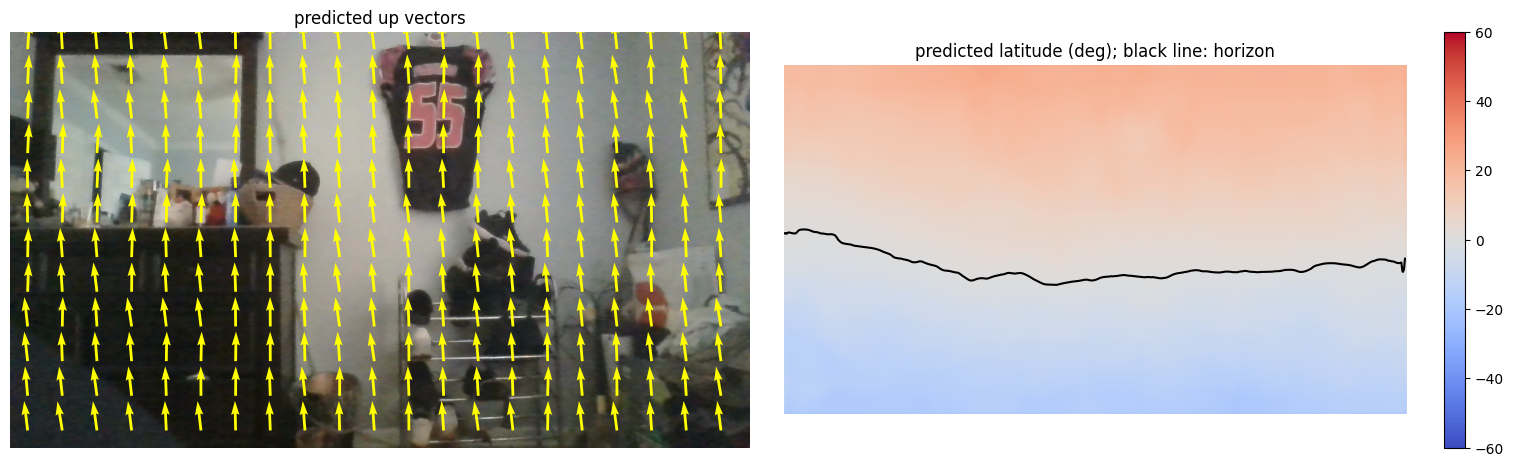

In [22]:
def show_fields(path, result, step=60):
    up = result["up_field"][0].cpu().numpy()
    lat = np.degrees(result["latitude_field"][0, 0].cpu().numpy())
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
    axes[0].imshow(load_rgb(path))
    yy, xx = np.mgrid[step // 2:H:step, step // 2:W:step]
    axes[0].quiver(xx, yy, up[0][yy, xx], up[1][yy, xx], color="yellow", angles="xy", scale=25)
    axes[0].set_title("predicted up vectors")
    im = axes[1].imshow(lat, cmap="coolwarm", vmin=-60, vmax=60)
    axes[1].contour(lat, levels=[0], colors="black")
    axes[1].set_title("predicted latitude (deg); black line: horizon")
    fig.colorbar(im, ax=axes[1])
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


show_fields(example, result)

### Task 2.1. The fields of a camera, by hand

Write `fields_by_hand(K, g, h, w)`. It returns the up field as an array of shape `(h, w, 2)` of unit vectors and the latitude field as an array of shape `(h, w)` in radians, using the formulas above. Use pixel centers: column $u$ of the image is at $u + 0.5$.

In [23]:
def fields_by_hand(K, g, h, w):
    u, v = np.meshgrid(np.arange(w) + 0.5, np.arange(h) + 0.5)

    x = (u - K[0, 2]) / K[0, 0]
    y = (v - K[1, 2]) / K[1, 1]

    up = np.stack([
        g[0] - g[2] * x,
        g[1] - g[2] * y
    ], axis=-1)

    up = up / np.linalg.norm(up, axis=-1, keepdims=True)

    rays = np.stack([x, y, np.ones_like(x)], axis=-1)
    rays = rays / np.linalg.norm(rays, axis=-1, keepdims=True)

    latitude = np.arcsin(np.clip(np.sum(rays * g, axis=-1), -1, 1))

    return up, latitude

In [24]:
def angle_between(a, b):
    return np.degrees(np.arccos(np.clip((a * b).sum(-1), -1, 1)))


g = gravity_of(result)
f_fit = float(result["camera"].f.squeeze()[0])
K_fit = np.array([[f_fit, 0, W / 2], [0, f_fit, H / 2], [0, 0, 1]])
up_mine, lat_mine = fields_by_hand(K_fit, g, H, W)
up_code, lat_code = get_perspective_field(result["camera"], result["gravity"])
d_up = np.median(angle_between(up_mine, up_code[0].permute(1, 2, 0).cpu().numpy()))
d_lat = np.degrees(np.median(np.abs(lat_mine - lat_code[0, 0].cpu().numpy())))
print(f"your fields vs GeoCalib's code for the same camera: up {d_up:.4f} deg, latitude {d_lat:.4f} deg")
assert d_up < 0.1 and d_lat < 0.1, "your fields should match GeoCalib's to well under 0.1 degrees"
print("passed")

your fields vs GeoCalib's code for the same camera: up 0.0021 deg, latitude 0.0288 deg
passed


### Task 2.2. The network against your checkerboard camera

The network's predicted fields are not exactly the fields of any camera. Measure how far they are from the fields of your **checkerboard** camera $\mathbf{K}$ (from Part 1) with the gravity GeoCalib found. Write `field_disagreement(result, K)`, which returns the median up-vector angle and the median latitude difference in degrees, over the more confident half of the pixels. Use `network_fields(result)` for the network's fields and confidence, `gravity_of(result)` for $\mathbf{g}$, your `fields_by_hand` for the camera's fields, and the provided `angle_between` for the angles.

In [25]:
def field_disagreement(result, K):
    up_network, lat_network, conf = network_fields(result)

    h, w = lat_network.shape
    g = gravity_of(result)

    up_camera, lat_camera = fields_by_hand(K, g, h, w)

    up_error = angle_between(up_network, up_camera)
    lat_error = np.degrees(np.abs(lat_network - lat_camera))

    threshold = np.median(conf)
    mask = conf >= threshold

    median_up = np.median(up_error[mask])
    median_lat = np.median(lat_error[mask])

    return median_up, median_lat

In [26]:
scene_results = {p.name: run(p) for p in SCENES}
for name, r in scene_results.items():
    d_up, d_lat = field_disagreement(r, K)
    print(f"{name:24s} up {d_up:5.2f} deg   latitude {d_lat:5.2f} deg")
    assert 0 <= d_up < 45 and 0 <= d_lat < 45
print("passed")

scene_000.png            up  1.71 deg   latitude  8.64 deg
scene_001.png            up  2.52 deg   latitude  6.11 deg
scene_002.png            up  1.27 deg   latitude  7.15 deg
scene_003.png            up  1.59 deg   latitude  2.62 deg
scene_004.png            up  1.89 deg   latitude  4.01 deg
scene_005.png            up  3.19 deg   latitude  6.06 deg
scene_006.png            up  1.19 deg   latitude  2.71 deg
scene_007.png            up  2.40 deg   latitude  5.57 deg
scene_008.png            up  0.78 deg   latitude  4.36 deg
scene_009.png            up  1.24 deg   latitude  5.42 deg
scene_010.png            up  2.82 deg   latitude  6.65 deg
scene_010_90.png         up  1.06 deg   latitude  3.10 deg
scene_011.png            up  2.83 deg   latitude  2.98 deg
scene_011_100.png        up  1.25 deg   latitude  2.25 deg
scene_012.png            up  3.61 deg   latitude  5.08 deg
scene_012_80.png         up  1.55 deg   latitude  3.23 deg
scene_013.png            up  3.11 deg   latitude  5.16 d

### Question 2.1. Three numbers from a field

Stage 2 fits only three numbers to a field of millions of pixels: the focal length and two angles of gravity. Explain how the fields determine each of them. Hint: what does the latitude do between the top and the bottom of the image, and what do the up vectors do far from the image center?

The latitude field is important to determining focal length because it describes how the viewing angle changes across the image, from top to bottom especially. A shorter focal length would produce a bigger change in latitude across the same number of pixels, and a longer focal length would produce a smaller change.

The up vectors help with determining the direction of gravity because they describe which way is vertically upward at each pixel. A camera's roll is estimated with the help of the up vectors' overall direction, and the pitch is determined with the help of the latitude field and the way the up vectors change across the image. Farther from the image center, the up vectors can change direction due to perspective, providing additional information about focal length and gravity orientation. GeoCalib can estimate the focal length and two gravity angles by fitting these patterns across the entire image.


### Question 2.2. Where the fields disagree

On which of your scenes do the network's fields disagree most with your checkerboard camera? Look at those images: what is missing in them that the network relies on?

The largest up-field disagreement occurred in scene_012.png at 3.61°, while the largest latitude disagreement occurred in scene_000.png at 8.64°. For scene_000, the image shows furniture (some tilted toward the camera) against a wall, with no view of the floor where this furniture sits. In scene_012, the camera is angled significantly upward toward the ceiling, with much of the lower room out of view, including the floor. These scenes might be more difficult for GeoCalib because they provide fewer useful perspective cues, such as the floor-wall boundary and horizontal surfaces that help establish the camera's orientation.

### Task 2.3. Calibrating from ordinary scenes

Using `scene_results` and the helpers, build a list of rows `(name, f, error_percent, f_uncertainty, roll_deg, pitch_deg)`, where `error_percent` compares GeoCalib's focal length with `F_REF` from Part 1. Then calibrate all scenes together with `calibrate_together(SCENES)` and store that focal length in `f_shared`.

In [27]:
rows = []

for name, result in scene_results.items():
    f = focal_of(result)
    error_percent = 100 * (f - F_REF) / F_REF
    f_uncertainty = focal_uncertainty_of(result)
    roll, pitch = roll_pitch_deg(result)

    rows.append((name, f, error_percent, f_uncertainty, roll, pitch))

shared_result = calibrate_together(SCENES)
f_shared = focal_of(shared_result)

In [28]:
print(f"{'scene':24s} {'f':>7s} {'error':>7s} {'unc.':>6s} {'roll':>6s} {'pitch':>6s}")
for name, f, err, unc, roll, pitch in rows:
    print(f"{name:24s} {f:7.1f} {err:+6.1f}% {unc:6.1f} {roll:+6.1f} {pitch:+6.1f}")
errs = np.array([r[2] for r in rows])
print(f"single scenes: median error {np.median(errs):+.1f}%, mean absolute {np.mean(np.abs(errs)):.1f}%")
print(f"all scenes together: f {f_shared:.1f} ({100 * (f_shared - F_REF) / F_REF:+.1f}%)")
assert len(rows) == len(SCENES) and all(len(r) == 6 for r in rows), "one row of six values per scene"
warn_unless(abs(f_shared - F_REF) < 0.3 * F_REF,
            "the pooled estimate is more than 30% from your checkerboard focal length; look at which scenes pull it away")
print("passed")

scene                          f   error   unc.   roll  pitch
scene_000.png              518.8  -42.5%  166.9   +1.3   +4.8
scene_001.png              734.5  -18.6%  143.3   +1.1   +7.5
scene_002.png              624.2  -30.9%  149.3   +0.3   +1.7
scene_003.png              911.6   +1.0%  177.6   -0.1   +4.2
scene_004.png              528.6  -41.5%  181.6   +0.4   +2.4
scene_005.png              762.6  -15.5%  278.4   +1.7   +1.5
scene_006.png              699.5  -22.5%  149.8   -0.1   -2.2
scene_007.png              499.6  -44.7%  204.3   -1.5   -2.4
scene_008.png             1193.1  +32.1%  531.4   -0.8   -1.1
scene_009.png              931.8   +3.2%  293.5   +0.2   +0.7
scene_010.png              746.6  -17.3%   42.2   +2.2  +23.3
scene_010_90.png           677.6  -25.0%  262.9   +0.5   -0.9
scene_011.png              854.9   -5.3%  106.0   +2.0   -8.8
scene_011_100.png          849.6   -5.9%  108.3   +0.6   +7.7
scene_012.png              646.1  -28.4%   56.6   +2.2  +18.3
scene_01

### Task 2.4. Reported uncertainty against the actual error

For each scene, compare the absolute focal error in pixels with the reported uncertainty. Store the fraction of scenes whose error is within the uncertainty in `covered`, and the correlation between the absolute error and the uncertainty in `corr`.

In [29]:
errors = np.array([abs(r[1] - F_REF) for r in rows])
uncertainties = np.array([r[3] for r in rows])

covered = np.mean(errors <= uncertainties)
corr = np.corrcoef(errors, uncertainties)[0, 1]

In [30]:
print(f"error within the reported uncertainty in {100 * covered:.0f}% of scenes; correlation {corr:+.2f}")
assert 0 <= covered <= 1 and -1 <= corr <= 1
print("passed")

error within the reported uncertainty in 47% of scenes; correlation +0.20
passed


### Task 2.5. Telling the network the focal length

GeoCalib accepts known parameters as priors. Calibrate every scene again with your checkerboard focal length fixed, `run(path, priors=focal_prior(F_REF))`, and store the change in pitch (with prior minus without, in degrees) per scene in `pitch_shift`.

In [31]:
pitch_shift = []

for p in SCENES:
    result_with_prior = run(p, priors=focal_prior(F_REF))

    _, pitch_with_prior = roll_pitch_deg(result_with_prior)
    _, pitch_without_prior = roll_pitch_deg(scene_results[p.name])

    pitch_shift.append(pitch_with_prior - pitch_without_prior)

In [32]:
for p, s, row in zip(SCENES, pitch_shift, rows):
    print(f"{p.name:24s} focal error without the prior {row[2]:+6.1f}%   pitch shift {s:+5.2f} deg")
assert len(pitch_shift) == len(SCENES)
print("passed")

scene_000.png            focal error without the prior  -42.5%   pitch shift +3.51 deg
scene_001.png            focal error without the prior  -18.6%   pitch shift +1.66 deg
scene_002.png            focal error without the prior  -30.9%   pitch shift +0.69 deg
scene_003.png            focal error without the prior   +1.0%   pitch shift -0.11 deg
scene_004.png            focal error without the prior  -41.5%   pitch shift +0.88 deg
scene_005.png            focal error without the prior  -15.5%   pitch shift +0.27 deg
scene_006.png            focal error without the prior  -22.5%   pitch shift -0.21 deg
scene_007.png            focal error without the prior  -44.7%   pitch shift -1.89 deg
scene_008.png            focal error without the prior  +32.1%   pitch shift +0.26 deg
scene_009.png            focal error without the prior   +3.2%   pitch shift +0.03 deg
scene_010.png            focal error without the prior  -17.3%   pitch shift +4.18 deg
scene_010_90.png         focal error withou

### Task 2.6. The gravity check

A phone inclinometer on the lid does not measure the camera's pitch directly: the app has its own zero, and the camera is not exactly perpendicular to the lid. But when the lid turns by some angle, the camera turns by the same angle. So compare **changes**. Fill `LID_READING` with your four tilt scenes and the phone reading for each, as `{"scene_tilt95_000.png": 95.0, ...}`, and set `BASELINE` to one of them. The provided cell compares each scene's change in phone reading from the baseline with its change in GeoCalib's pitch.

The phone reading grows as you tilt the lid back, and tilting the lid back points the camera up, which GeoCalib reports as a larger pitch. If your app counts the other way, set `READING_SIGN = -1`. The sample data has no lid readings, so this task runs only on your own captures.

In [33]:
LID_READING = {
    "scene_010_90.png": 90.0,
    "scene_011_100.png": 100.0,
    "scene_012_80.png": 80.0,
    "scene_013_70.png": 70.0,
}

BASELINE = "scene_010_90.png"
READING_SIGN = 1

In [34]:
pitch_of = {r[0]: r[5] for r in rows}
if not LID_READING:
    print("no lid readings: add your tilt scenes to LID_READING (only possible with your own captures)")
else:
    assert BASELINE in LID_READING, "set BASELINE to one of the scenes in LID_READING"
    missing = [n for n in LID_READING if n not in pitch_of]
    assert not missing, f"not among your scenes: {missing}"
    print(f"{'scene':24s} {'lid change':>10s} {'pitch change':>12s} {'difference':>10s}")
    for name, reading in LID_READING.items():
        d_lid = READING_SIGN * (reading - LID_READING[BASELINE])
        d_pitch = pitch_of[name] - pitch_of[BASELINE]
        print(f"{name:24s} {d_lid:+10.1f} {d_pitch:+12.1f} {d_pitch - d_lid:+10.1f} deg")

scene                    lid change pitch change difference
scene_010_90.png               +0.0         +0.0       +0.0 deg
scene_011_100.png             +10.0         +8.7       -1.3 deg
scene_012_80.png              -10.0         -7.3       +2.7 deg
scene_013_70.png              -20.0        -16.4       +3.6 deg


### Question 2.3. One scene against all scenes

Is GeoCalib's focal length closer to your checkerboard value from one scene or from all scenes together? Does its reported uncertainty predict which scenes are wrong? Use your numbers.

GeoCalib's focal length was closer to my checkerboard calibration when using all scenes together. My checkerboard focal length was 900.1px while the GeoCalib estimate was 775.5px, this is an error of ~14%. The individual scenes had a mean absolute error of 20.9%, with some of these scenes actually being much closer at only 1.0% error. The reported uncertainty was not very reliable at predicting which scenes were wrong. Only 47% had errors within reported uncertainty, and the correlation of +0.20, indicates a weak positive relationship between reported uncertainty and actual error.

### Question 2.4. Focal length and pitch

How much does knowing the focal length change the pitch, and why are the two connected?

Giving my checkerboard focal length to GeoCalib changed its estimated pitch by a variety of amounts based on the scene. The median absolute change was about 0.69 deg, with largest decrease being in scene_007 with -1.89 deg and the largest increase being in scene_012 with +5.86 deg. Focal length and pitch are connected because they both affect how the scene's perspective is displayed in the image. Changing pitch shifts the camera's viewing direction, while a shorter focal length causes a wider fov. Since both affect the apparent position of the horizon and the latitude field, an incorrect focal length can cause GeoCalib to compensate by adjusting its estimated pitch.

## Part 3. Calibration from a person walking, as in NVIDIA AutoMagicCalib (25 points)

NVIDIA's [AutoMagicCalib](https://github.com/NVIDIA-AI-IOT/auto-magic-calib) calibrates cameras from people walking. One camera can do part of this with single-view geometry (Lv, Zhao and Nevatia, "Camera calibration from video of a walking human", IEEE TPAMI 2006). The background is in the section [Single View Metrology](https://aegean.ai/aiml-common/lectures/3d-reconstruction/single-view-metrology/index); three facts go beyond it.

**A person is a vertical ruler.** When you stand upright, the line from your feet to your head is vertical in the world. All such lines are parallel in 3D, so in the image they meet at the **vertical vanishing point** $\mathbf{v}_z$. Your head is always about the same height above the floor, so for two of your positions the line through the two head points and the line through the two foot points are parallel in 3D, horizontal, and meet on the **horizon line**.

**Two vanishing points give the focal length.** With square pixels, zero skew and the principal point $\mathbf{c}$ known, the vanishing points of two orthogonal directions satisfy $(\mathbf{v}_1 - \mathbf{c}) \cdot (\mathbf{v}_2 - \mathbf{c}) = -f^2$. This is the special case of the constraint $\mathbf{v}_i^\top \mathbf{K}^{-\top} \mathbf{K}^{-1} \mathbf{v}_j = 0$ from Single View Metrology. Every point $\mathbf{p}$ on the horizon is the vanishing point of a horizontal direction, so take the point of the horizon closest to $\mathbf{c}$.

**Far vanishing points.** A laptop webcam looks almost horizontally, so the vertical vanishing point lies thousands of pixels outside the image and the head-foot lines are nearly parallel. Their intersection is then sensitive to small errors and can even land on the wrong side of the image. It must lie on the opposite side of $\mathbf{c}$ from the horizon: a camera that looks up sees the horizon below the center and $\mathbf{v}_z$ far above it.

**What is graded in this part.** You write the projective geometry: lines and intersections in homogeneous coordinates, then the focal length and the tilt from the vanishing point and the horizon. The tilt is checked against GeoCalib on a frame of the same video. You also compute a focal length, but at laptop pitch it cannot be pinned down from a walking person, and Question 3.1 asks you to explain why. It is graded on that explanation, not on its accuracy.

**Provided.** Reads every fourth frame of your walking video.

In [35]:
def read_frames(path, step=4):
    cap = cv2.VideoCapture(str(path))
    frames, i = [], 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if i % step == 0:
            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        i += 1
    return frames


VIDEO = VIDEOS[-1]  # the latest recording in session.json; set this to another file in VIDEOS to analyze a different take
print("recordings:", [v.name for v in VIDEOS])
frames = read_frames(VIDEO)
print(f"{len(frames)} frames from {VIDEO.name}")

recordings: ['walk_000.mp4', 'walk_001.mp4']
470 frames from walk_001.mp4


Enter the phone reading you took on the lid before recording the video, read the same way as in Task 2.6. It is used only to compare changes in tilt, so leave it as `None` if you did not take one.

In [36]:
LID_DURING_VIDEO = 90  # the phone reading on the lid during the video

### Head and foot points

A person box is not enough here. Its top center and bottom center have the same $x$, so every head-foot line would be exactly vertical in the image, and exactly parallel lines carry no information about where $\mathbf{v}_z$ is. You need points on the body itself. The Keypoint R-CNN from torchvision is the Faster R-CNN you trained in Assignment 2 with an extra head that predicts 17 COCO body keypoints per person. Keypoints 1 and 2 are the eyes, 5 and 6 the shoulders, 15 and 16 the ankles.

**Provided.** `detect_points(frames, head=(1, 2))` runs the detector on every frame and returns the head points (the midpoint of the eyes) and the foot points (the midpoint of the ankles). Eye height is as constant as head height, so the horizon construction still works. It handles two problems found in real footage: more than one "person" may be detected (a framed photo on the wall counts), so it keeps the **tallest** detection with a score above 0.9; and feet or eyes may be cut off or hidden, so it skips frames where any of those keypoints has a score below 3. Finally it removes the lens distortion from the points with your Part 1 calibration, because the vanishing-point formulas below assume a pinhole camera.

In [37]:
detector = torchvision.models.detection.keypointrcnn_resnet50_fpn(weights="DEFAULT").eval().to(DEVICE)


@torch.no_grad()
def head_and_foot(frame, head=(1, 2)):
    out = detector([to_tensor(frame)])[0]
    keep = torch.nonzero(out["scores"] > 0.9).flatten()
    if len(keep) == 0:
        return None
    heights = out["boxes"][keep, 3] - out["boxes"][keep, 1]
    j = keep[int(torch.argmax(heights))]
    kp = out["keypoints"][j].cpu().numpy()
    ks = out["keypoints_scores"][j].cpu().numpy()
    if min(ks[list(head) + [15, 16]]) < 3:
        return None
    return kp[list(head), :2].mean(0), kp[[15, 16], :2].mean(0)


def undistort_points(pts):
    return cv2.undistortPoints(pts.reshape(-1, 1, 2).astype(np.float64), K, dist, P=K).reshape(-1, 2)


def detect_points(frames, head=(1, 2)):
    found = [hf for hf in (head_and_foot(f, head) for f in frames) if hf is not None]
    if not found:
        return np.empty((0, 2)), np.empty((0, 2))
    return undistort_points(np.array([p[0] for p in found])), undistort_points(np.array([p[1] for p in found]))


heads, feet = detect_points(frames)
print(f"usable detections in {len(heads)} of {len(frames)} frames")
# the horizon step needs 200 pairs of positions, and 21 frames are the fewest that give that many (21 * 20 / 2 = 210)
assert len(heads) >= 21, "fewer than 21 usable frames: keep your whole body, eyes and ankles included, in view"
print(f"eye-to-ankle height in the image: {np.min(feet[:, 1] - heads[:, 1]):.0f} to {np.max(feet[:, 1] - heads[:, 1]):.0f} px")
warn_unless(len(heads) >= 30, "fewer than 30 usable frames: the vanishing point and the horizon will be noisy")

Downloading: "https://download.pytorch.org/models/keypointrcnn_resnet50_fpn_coco-fc266e95.pth" to /root/.cache/torch/hub/checkpoints/keypointrcnn_resnet50_fpn_coco-fc266e95.pth


100%|██████████| 226M/226M [00:01<00:00, 181MB/s]


usable detections in 319 of 470 frames
eye-to-ankle height in the image: 411 to 745 px


### Task 3.1. Lines and intersections in homogeneous coordinates

Write a pixel $(x, y)$ as the homogeneous point $(x, y, 1)$. A line is a vector $\mathbf{l} = (a, b, c)$ of the points with $\mathbf{l} \cdot (x, y, 1) = ax + by + c = 0$. Two facts from Single View Metrology do all the work:

- the line through two points $\mathbf{p}$ and $\mathbf{q}$ is $\mathbf{p} \times \mathbf{q}$;
- the intersection of two lines $\mathbf{l}_1$ and $\mathbf{l}_2$ is $\mathbf{l}_1 \times \mathbf{l}_2$. Divide by its last entry to get the pixel; a last entry of 0 means the lines are parallel and meet at infinity.

Write `line_through(p, q)`, which returns the line through two pixels scaled so that $a^2 + b^2 = 1$ (then $\mathbf{l} \cdot (x, y, 1)$ is the signed distance of a pixel from the line), or `None` when the two pixels coincide. Write `intersect(l1, l2)`, which returns the homogeneous intersection without dividing.

In [38]:
def line_through(p, q):
    p = np.array([p[0], p[1], 1.0])
    q = np.array([q[0], q[1], 1.0])

    line = np.cross(p, q)

    norm = np.linalg.norm(line[:2])
    if norm == 0:
        return None

    return line / norm


def intersect(l1, l2):
    return np.cross(l1, l2)

In [39]:
l = line_through((0, 0), (2, 2))
assert l is not None and abs(np.linalg.norm(l[:2]) - 1) < 1e-9, "scale the line so that a^2 + b^2 = 1"
for pt in [(0, 0), (2, 2), (5, 5)]:
    assert abs(l @ [pt[0], pt[1], 1]) < 1e-9, f"{pt} should lie on the line through (0, 0) and (2, 2)"
assert np.isclose(abs(line_through((0, 0), (3, 0)) @ [1, 4, 1]), 4), "l . (x, y, 1) should be the distance from the line"
assert line_through((1, 1), (1, 1)) is None, "return None when the two pixels coincide"
x = intersect(line_through((1, 0), (1, 5)), line_through((0, 2), (7, 2)))
assert np.allclose(x[:2] / x[2], [1, 2]), "the lines x = 1 and y = 2 meet at (1, 2)"
par = intersect(line_through((0, 0), (1, 0)), line_through((0, 1), (1, 1)))
assert abs(par[2]) < 1e-9, "parallel lines meet at infinity: the last entry should be 0"
print("passed")

passed


**Provided.** `person_geometry(heads, feet)` uses your two functions. It finds the vertical vanishing point $\mathbf{v}_z$ as the point that most head-foot lines pass through (RANSAC), intersects the head-head and foot-foot lines of up to 2000 pairs of your positions that are far enough apart, and fits the horizon to those intersections (RANSAC again). Nearly parallel lines meet far away and their intersections are noisy, which is why both fits are robust.

In [40]:
RNG = np.random.default_rng(0)


def ransac_common_point(lines, starts, ends, iters=2000, tol_deg=0.5):
    # A point that most lines pass through. Inliers: lines whose direction points at it within tol_deg.
    best = None
    dirs = (ends - starts) / np.linalg.norm(ends - starts, axis=1, keepdims=True)
    mids = (starts + ends) / 2
    for _ in range(iters):
        a, b = RNG.choice(len(lines), 2, replace=False)
        v = intersect(lines[a], lines[b])
        if abs(v[2]) < 1e-12:
            continue
        to_v = v[:2] / v[2] - mids
        to_v /= np.linalg.norm(to_v, axis=1, keepdims=True)
        ang = np.degrees(np.arcsin(np.clip(np.abs(dirs[:, 0] * to_v[:, 1] - dirs[:, 1] * to_v[:, 0]), 0, 1)))
        inliers = ang < tol_deg
        if best is None or inliers.sum() > best.sum():
            best = inliers
    v = np.linalg.svd(lines[best])[2][-1]
    return v / v[2], best


def ransac_line(points, iters=2000, tol_px=20):
    best = None
    for _ in range(iters):
        a, b = RNG.choice(len(points), 2, replace=False)
        l = line_through(points[a], points[b])
        if l is None:
            continue
        inliers = np.abs(np.c_[points, np.ones(len(points))] @ l) < tol_px
        if best is None or inliers.sum() > best.sum():
            best = inliers
    pts = points[best]
    m = pts.mean(0)
    d = np.linalg.svd(pts - m)[2][0]
    return line_through(m, m + d), best


def eligible_pairs(feet, min_fraction=0.08, max_pairs=2000, min_pairs=200):
    # Index pairs (a, b) whose foot points are at least min_fraction of the image width apart.
    # Close pairs give nearly parallel lines whose intersection is mostly noise.
    a, b = np.triu_indices(len(feet), k=1)
    far = np.linalg.norm(feet[a] - feet[b], axis=1) >= min_fraction * W
    a, b = a[far], b[far]
    if len(a) < min_pairs:
        raise ValueError(f"only {len(a)} pairs of positions are {min_fraction:.0%} of the image width apart: "
                         "walk across more of the room, or recapture the video")
    pick = RNG.choice(len(a), min(max_pairs, len(a)), replace=False)
    return list(zip(a[pick], b[pick]))


def person_geometry(heads, feet):
    vertical_lines = np.array([line_through(h, f) for h, f in zip(heads, feet)])
    vz, _ = ransac_common_point(vertical_lines, feet, heads)
    horizon_points = []
    for a, b in eligible_pairs(feet):
        lh, lf = line_through(heads[a], heads[b]), line_through(feet[a], feet[b])
        if lh is None or lf is None:
            continue
        p = intersect(lh, lf)
        if abs(p[2]) > 1e-9 and np.all(np.abs(p[:2] / p[2]) < 1e6):
            horizon_points.append(p[:2] / p[2])
    horizon_points = np.array(horizon_points)
    horizon, horizon_inliers = ransac_line(horizon_points)
    return vz, horizon, horizon_points, horizon_inliers


vz, horizon, horizon_points, horizon_inliers = person_geometry(heads, feet)
row_at_center = -(horizon[2] + horizon[0] * W / 2) / horizon[1]
print(f"vertical vanishing point ({vz[0]:.0f}, {vz[1]:.0f}); horizon crosses the image center column at row {row_at_center:.0f}")

vertical vanishing point (1888, -17537); horizon crosses the image center column at row 391


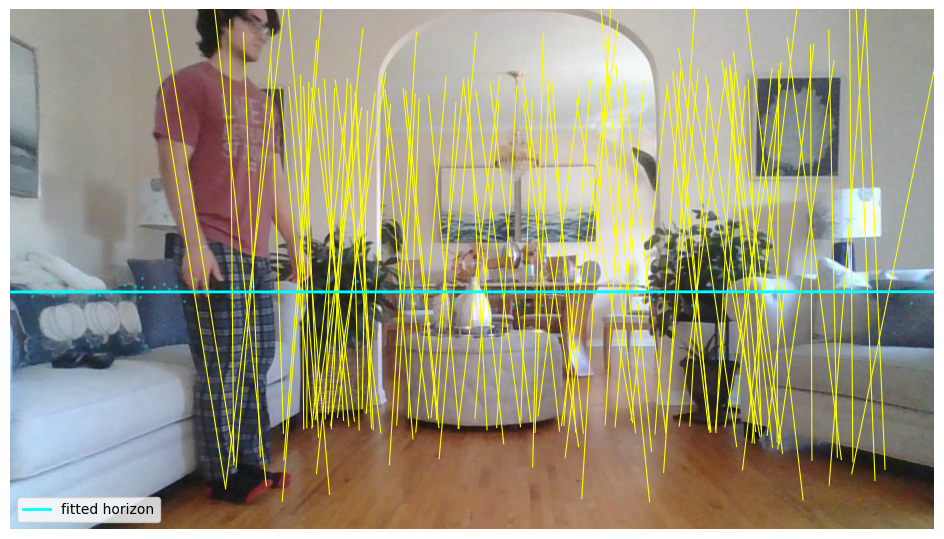

In [41]:
fig, ax = plt.subplots(figsize=(12, 6.75))
ax.imshow(cv2.undistort(frames[len(frames) // 2], K, dist))
for h_, f_ in zip(heads[::3], feet[::3]):
    ax.plot([h_[0], f_[0]], [h_[1], f_[1]], color="yellow", linewidth=0.8)
xs = np.array([0, W])
ax.plot(xs, -(horizon[2] + horizon[0] * xs) / horizon[1], color="cyan", linewidth=2, label="fitted horizon")
ax.scatter(horizon_points[horizon_inliers][:, 0], horizon_points[horizon_inliers][:, 1], s=2, color="cyan", alpha=0.3)
ax.set_xlim(0, W)
ax.set_ylim(H, 0)
ax.legend()
ax.axis("off")
plt.show()

### Task 3.2. Focal length and tilt

Write `focal_and_pitch(vz, horizon, c, f_known)`. Let $\mathbf{p}$ be the point of the horizon closest to $\mathbf{c}$ and $d_h = \lVert \mathbf{p} - \mathbf{c} \rVert$. Return three things:

- `f_vp`: the focal length from $(\mathbf{v}_z - \mathbf{c}) \cdot (\mathbf{p} - \mathbf{c}) = -f^2$, or `nan` if the right-hand side is not positive;
- `pitch_deg`: the camera's pitch, $\arctan(d_h / f)$ using `f_known`, positive when the camera looks up (horizon below the center);
- `sign_ok`: whether $\mathbf{v}_z$ lies on the opposite side of $\mathbf{c}$ from the horizon.

The check first tests your function on a synthetic camera, then runs it on your video with $\mathbf{c}$ set to the principal point from Part 1.

In [42]:
def focal_and_pitch(vz, horizon, c, f_known):
    vz_xy = vz[:2] / vz[2]

    a, b, d = horizon
    distance = (a*c[0] + b*c[1] + d) / (a*a + b*b)

    p = c - distance * np.array([a, b])
    dh = np.linalg.norm(p - c)

    f_squared = -np.dot(vz_xy - c, p - c)
    f_vp = np.sqrt(f_squared) if f_squared > 0 else np.nan

    pitch_deg = np.degrees(np.arctan(dh / f_known))

    if p[1] < c[1]:
        pitch_deg = -pitch_deg

    sign_ok = np.dot(vz_xy - c, p - c) < 0

    return f_vp, pitch_deg, bool(sign_ok)


In [43]:
# a synthetic camera with f = 1000 px looking up by 10 degrees: horizon below the center, vz far above it
c_syn, f_syn, t = np.array([640.0, 360.0]), 1000.0, np.radians(10)
vz_syn = np.array([c_syn[0], c_syn[1] - f_syn / np.tan(t), 1.0])
horizon_syn = np.array([0.0, 1.0, -(c_syn[1] + f_syn * np.tan(t))])
f_t, pitch_t, sign_t = focal_and_pitch(vz_syn, horizon_syn, c_syn, f_syn)
assert abs(f_t - f_syn) < 1e-6 * f_syn, f"synthetic camera: focal length {f_t:.1f} instead of {f_syn:.0f}"
assert abs(pitch_t - 10) < 1e-6 and sign_t, f"synthetic camera: pitch {pitch_t:+.2f} instead of +10, sign_ok {sign_t}"
_, pitch_down, _ = focal_and_pitch(np.array([640.0, 360 + f_syn / np.tan(t), 1.0]), np.array([0.0, 1.0, -(360 - f_syn * np.tan(t))]), c_syn, f_syn)
assert abs(pitch_down + 10) < 1e-6, "a camera looking down should get a negative pitch"

c = np.array([K[0, 2], K[1, 2]])  # the principal point from Part 1
f_vp, pitch_person, sign_ok = focal_and_pitch(vz, horizon, c, F_REF)
print(f"focal length from the person {f_vp:.1f} px ({100 * (f_vp - F_REF) / F_REF:+.1f}% vs the checkerboard)")
print(f"pitch {pitch_person:+.2f} deg; vertical vanishing point on the correct side: {sign_ok}")
pitch_net = roll_pitch_deg(model.calibrate(to_tensor(frames[len(frames) // 2])))[1]
print(f"GeoCalib on a frame of the same video: pitch {pitch_net:+.2f} deg")
warn_unless(abs(pitch_person - pitch_net) < 5, "the person and GeoCalib disagree on the tilt by more than 5 degrees")
if LID_DURING_VIDEO is not None and BASELINE in LID_READING:
    d_lid = READING_SIGN * (LID_DURING_VIDEO - LID_READING[BASELINE])
    d_pitch = pitch_person - pitch_of[BASELINE]
    print(f"change from the baseline scene: lid {d_lid:+.1f} deg, pitch from the person {d_pitch:+.1f} deg")
print("passed")

focal length from the person nan px (+nan% vs the checkerboard)
pitch -0.25 deg; vertical vanishing point on the correct side: False
GeoCalib on a frame of the same video: pitch +0.95 deg
change from the baseline scene: lid +0.0 deg, pitch from the person +0.7 deg
passed


**Provided.** The same pipeline with the midpoint of the shoulders (keypoints 5 and 6) as the head point instead of the eyes, for Question 3.1.

In [44]:
heads_s, feet_s = detect_points(frames, head=(5, 6))
vz_s, horizon_s, _, _ = person_geometry(heads_s, feet_s)
f_vp_s, pitch_s, sign_s = focal_and_pitch(vz_s, horizon_s, c, F_REF)
print(f"eyes:      f {f_vp:7.1f} px ({100 * (f_vp - F_REF) / F_REF:+6.1f}%)   pitch {pitch_person:+.2f} deg   vz on the correct side: {sign_ok}")
print(f"shoulders: f {f_vp_s:7.1f} px ({100 * (f_vp_s - F_REF) / F_REF:+6.1f}%)   pitch {pitch_s:+.2f} deg   vz on the correct side: {sign_s}")

eyes:      f     nan px (  +nan%)   pitch -0.25 deg   vz on the correct side: False
shoulders: f   420.4 px ( -53.4%)   pitch -0.20 deg   vz on the correct side: True


### Question 3.1. Tilt against focal length

How close are your tilt and your focal length to the references? Explain why the tilt is much more reliable than the focal length. Use $d_z = f^2 / d_h$ for the distance of the vertical vanishing point from the image center. Then compare the eye and shoulder runs above: how much did the focal length change, how much did the tilt change, and why?

GeoCalib estimated a pitch of +0.95 deg, compared to my eye-based walking calibration which estimated a pitch of -0.25 deg, giving a difference of 1.2 deg. However, the eye-based walking calibration couldn't produce a valid focal length because the estimated vertical vanishing point was on the wrong side of the image center. The shoulder-based method estimated 420.4px, which is 53.4% below my checkerboard reference of ~900px. The pitch is more reliable because it comes from the horizon's position. On the other hand, the focal length also depends on the vertical vanishing point. Using the given equation, when the camera is almost level, d_h becomes very small and the vanishing point moves very far away, making its position sensitive to small detection errors. The switch from eyes to shoulders caused the focal length to go from invalid to 420.4px, while pitch barely changed (from -0.25 deg to -0.2 deg, a difference of 0.05 deg). The focal length is much less stable than the pitch

### Question 3.2. The side of the vertical vanishing point

Did your vertical vanishing point land on the correct side? If it had not, what would $f^2$ have been, and what does that tell you about intersecting nearly parallel lines?

The eye-based vertical vanishing point did not land on the correct side, as shown by sign_ok = False. This made f^2 negative, meaning there was no valid real focal length, so my function returned NaN. When the camera is nearly level, the head-to-foot lines can be nearly parallel in the image. Their intersection is extremely sensitive to small detection errors, which can move the estimated vanishing point very far away or to the wrong side. This shows that intersecting nearly parallel lines can produce unreliable calibration results.

## Part 4. Comparison (15 points)

Answer each question in a short paragraph, using your results. For the last question, read sections 44.2 and 44.3 of the MIT book's chapter on [multiview geometry and structure from motion](https://visionbook.mit.edu/multiview.html).

### Question 4.1. What each method relies on

What does each of the three methods rely on to calibrate the camera, and in what kind of scene or recording does each one fail?

Checkerboard calibration relies on using known dimensions to detect corners of a pattern from multiple camera angles. It works well when the checkerboard is clearly visible, but becomes unreliable if the images are blurry or are mostly taken from the front.

GeoCalib uses a neural network to predict perspective fields from ordinary images and estimate focal length and gravity. It becomes less reliable on scenes where perspective is hard to observe, like flat walls or pictures without floors.

The walking person method uses detected head and foot positions to estimate the vertical vanishing point and horizon. It struggles when keypoint detections are noisy or when the camera is nearly level. This is because the head-to-foot lines become almost parallel and estimate for focal-length becomes unstable.

### Question 4.2. Ranking the methods

Rank the three methods by the accuracy of the focal length and of the tilt on your data, and explain the ranking.

For focal length, I rank checkerboard calibration first, then GeoCalib, and then the walking-person method third. The checkerboard calibration was stable at 900.1px with an RMS error of 0.935px, as well as a leave-one-out spread of only 1.4%. GeoCalib estimated 775.5px using all the scenes, which was 14% below the checkerboard result. The walking-person method produced a invalid focal length from eye positions and 420.4px from shoulder positions.

For tilt, a three-way comparison is more difficult because GeoCalib and the walking-person method estimate tilt relative to the world's vertical direction, while checkerboard estimates the camera rotation relative to the checkerboard. I would rank GeoCalib first and the walking-person method second for tilt, although this ranking is less certain. I would say that GeoCalib had the strongest evidence of accuracy because its estimated changed were within 1.3 deg to 3.6 deg of my measured laptop lid changes. It is interesting to note though, that the walking-person method seems to be relatively stable, as it was able to produce relatively consistent pitch estimates of -0.25 deg and -0.2 deg, differing by only 0.05 deg.

### Question 4.3. One webcam against AutoMagicCalib

AutoMagicCalib calibrates several fixed cameras from pedestrian trajectories, matches tracklets of the same person across cameras, and refines all cameras jointly with bundle adjustment. Which of these steps can one webcam reproduce, which can it not, and what does bundle adjustment minimize?

With one webcam, I can:

 - Detect a person's keypoints and track their movement across frames
 - Estimate the vertical vanishing point and horizon
 - Use the above to calculate camera pitch and focal length

 However, I can't match the same pedestrian across different cameras or jointly calibrate multiple camera viewpoints like AutoMagicCalib does. Also, overlapping camera views provide additional geometric constraints that one webcam cannot provide.

 Bundle adjustment improves a reconstruction by jointly optimizing camera parameters and 3D point positions to minimize the sum of squared reprojection errors, the difference between where a point is actually observed in an image and the predicted point.

## Your captures

Share your `captures` folder in Google Drive with view access (Share, General access, Anyone with the link, Viewer), and paste the link below. Graders use it to check your data.

In [3]:
CAPTURES_SHARE_LINK = "https://drive.google.com/drive/folders/1Td5TBNd8mgnR3cp2Tx6HedW6AaXZ6sfQ?usp=sharing"  # paste the view-only link to your captures folder
print("data used in this notebook:", DATA, "| shared folder:", CAPTURES_SHARE_LINK or "not provided")

data used in this notebook: /content/drive/MyDrive/cv-midterm/captures | shared folder: https://drive.google.com/drive/folders/1Td5TBNd8mgnR3cp2Tx6HedW6AaXZ6sfQ?usp=sharing
